In [ ]:
#%pip install langgraph

Note: you may need to restart the kernel to use updated packages.


In [1]:
from langchain_openai import ChatOpenAI

# 모델 초기화
model = ChatOpenAI(model="gpt-4o-mini")
model.invoke('안녕하세요!')

AIMessage(content='안녕하세요! 어떻게 도와드릴까요?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 10, 'prompt_tokens': 10, 'total_tokens': 20, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_20eb127183', 'id': 'chatcmpl-EjyRp6uuM21CT7Q89Htu4gSUpxdQM', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1d808-f397-7175-8894-c894d341c7ab-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 10, 'output_tokens': 10, 'total_tokens': 20, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})

In [2]:
from typing import Annotated # annotated는 타입 힌트를 사용할 때 사용하는 함수
from typing_extensions import TypedDict # TypedDict는 딕셔너리 타입을 정의할 때 사용하는 함수

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

class State(TypedDict):	#①
    """
    State 클래스는 TypedDict를 상속받습니다.

    속성:
        messages (Annotated[list[str], add_messages]): 메시지들은 "list" 타입을 가집니다.   #②
       'add_messages' 함수는 이 상태 키가 어떻게 업데이트되어야 하는지를 정의합니다.  #③
        (이 경우, 메시지를 덮어쓰는 대신 리스트에 추가합니다)
    """
    messages: Annotated[list[str], add_messages]	#②

# StateGraph 클래스를 사용하여 State 타입의 그래프를 생성합니다.
graph_builder = StateGraph(State) #④

In [3]:
def generate(state: State):	#①
    """
    주어진 상태를 기반으로 챗봇의 응답 메시지를 생성합니다.

    매개변수:
    state (State): 현재 대화 상태를 나타내는 객체로, 이전 메시지들이 포함되어 있습니다.
		
    반환값:
    dict: 모델이 생성한 응답 메시지를 포함하는 딕셔너리. 
          형식은 {"messages": [응답 메시지]}입니다.
    """ 
    return {"messages": [model.invoke(state["messages"])]}	#②

graph_builder.add_node("generate", generate)	#③

In [4]:
graph_builder.add_edge(START, "generate")
graph_builder.add_edge("generate", END)    

graph = graph_builder.compile()

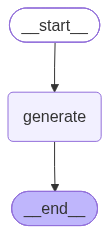

In [5]:
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception: 
    pass

In [6]:
response = graph.invoke({"messages": ["안녕하세요! 저는 이성용입니다"]})

print(type(response))
response

<class 'dict'>


{'messages': [HumanMessage(content='안녕하세요! 저는 이성용입니다', additional_kwargs={}, response_metadata={}, id='a7d89913-78de-4bf9-8a29-3646f6d711ab'),
  AIMessage(content='안녕하세요, 이성용님! 어떻게 도와드릴까요?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 15, 'prompt_tokens': 15, 'total_tokens': 30, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_eb86cfd659', 'id': 'chatcmpl-EjyWaLl8Pci8UftX6B67U3GjsCwd0', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1d80d-7749-75ec-8591-11a14c99dc51-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 15, 'output_tokens': 15,

In [7]:
response["messages"].append("제 이름을 아시나요?")
graph.invoke(response)

{'messages': [HumanMessage(content='안녕하세요! 저는 이성용입니다', additional_kwargs={}, response_metadata={}, id='a7d89913-78de-4bf9-8a29-3646f6d711ab'),
  AIMessage(content='안녕하세요, 이성용님! 어떻게 도와드릴까요?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 15, 'prompt_tokens': 15, 'total_tokens': 30, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_eb86cfd659', 'id': 'chatcmpl-EjyWaLl8Pci8UftX6B67U3GjsCwd0', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1d80d-7749-75ec-8591-11a14c99dc51-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 15, 'output_tokens': 15,

In [8]:
inputs = {"messages": [("human", "한국과 일본의 관계에 대해 자세히 알려줘")]}
for chunk, _ in graph.stream(inputs, stream_mode="messages"):
    print(chunk.content, end="")

한국과 일본의 관계는 역사적으로 복잡하고 다층적입니다. 두 나라의 관계는 다음과 같은 여러 요인들에 의해 형성되었습니다:

### 역사적 배경
1. **일제강점기**: 1910년부터 1945년까지 일본은 한국을 식민지로 지배했습니다. 이 시기는 한국 역사에서 매우 아픈 기억으로 남아 있으며, 강제노동, 성노예(위안부) 문제 등이 발생했습니다. 이러한 역사적 경험은 현재까지도 두 나라 간의 긴장 관계에 큰 영향을 미치고 있습니다.

2. **전후 관계**: 제2차 세계대전 이후, 일본은 한국과의 관계를 개선하기 위해 여러 조치를 취했습니다. 1965년 한일기본조약을 체결하여 외교 관계를 정상화하고 경제 협력을 시작했으나, 역사 문제와 관련한 갈등은 여전히 존재했습니다.

### 경제적 상호작용
양국은 경제적으로 깊은 관계를 맺고 있으며, 투자와 무역이 활발히 이루어지고 있습니다. 한국은 일본으로부터 기술과 자원을 수입하고, 일본은 한국 시장에서 중요한 소비시장으로 자리 잡고 있습니다.

### 문화 교류
K-POP, 드라마, 영화와 같은 한국의 대중문화가 일본에서 큰 인기를 끌고 있으며, 반대로 일본의 애니메이션, 만화, 문화도 한국에서 인기가 많습니다. 이러한 문화 교류는 양국 간의 이해를 증진하는 데 기여하고 있습니다.

### 정치적 갈등
1. **위안부 및 강제징용 문제**: 역사 문제는 여전히 중요한 갈등 요소입니다. 한국에서는 일본의 잔혹한 식민지 지배에 대한 사과와 배상을 요구하고 있으며, 일본 정부는 이에 대해 의견이 갈리는 경향이 있습니다.

2. **영토 분쟁**: 독도(다케시마)에 대한 영유권 문제는 한국과 일본 간의 또 다른 갈등 요소입니다. 두 국가는 각자 자신들의 주장을 고수하고 있습니다.

3. **안보 문제**: 북한의 핵무장과 군사적 위협은 한국과 일본이 협력해야 하는 이유 중 하나입니다. 양국 간의 안보 협력은 미국과의 삼각 동맹으로 강화되고 있습니다.

### 최근 동향
최근 몇 년 동안 한국과 일본 간의 관계는 여러 사건과 이

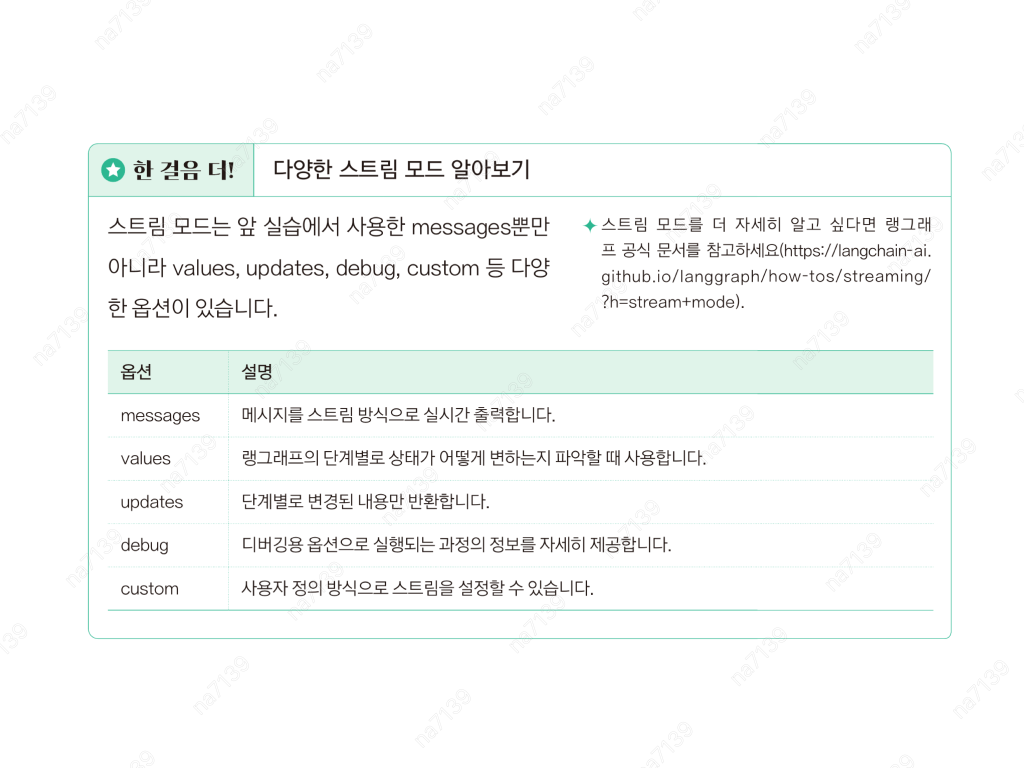